# Retail Sales Forecasting

## Project Overview

This project aims to analyse historical retail sales
data and forecast future sales using Python.

## Objectives

1. Clean and preprocess retail transaction data.
2. Perform Exploratory Data Analysis (EDA).
3. Identify sales trends and seasonal patterns.
4. Build forecasting models.
5. Evaluate model performance.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook
  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 2.3.0
NumPy version: 2.2.6


In [2]:
from pathlib import Path

print("Current notebook location:")
print(Path.cwd())

Current notebook location:
C:\Users\Rathika\Documents\Data_Science_Portfolio\01_Retail_Sales_Forecasting\notebooks


In [3]:
from pathlib import Path

# Create project folders
project_folder = Path.cwd() / "01_Retail_Sales_Forecasting"

(project_folder / "data").mkdir(parents=True, exist_ok=True)
(project_folder / "notebooks").mkdir(exist_ok=True)
(project_folder / "images").mkdir(exist_ok=True)

print("Project folders created!")
print(project_folder)

Project folders created!
C:\Users\Rathika\Documents\Data_Science_Portfolio\01_Retail_Sales_Forecasting\notebooks\01_Retail_Sales_Forecasting


In [4]:
import pandas as pd
from pathlib import Path

In [5]:
file_path = (
    Path.home()
    / "Documents"
    / "Data_Science_Portfolio"
    / "01_Retail_Sales_Forecasting"
    / "data"
    / "Online Retail.xlsx"
)

print(file_path)
print("File exists:", file_path.exists())

C:\Users\Rathika\Documents\Data_Science_Portfolio\01_Retail_Sales_Forecasting\data\Online Retail.xlsx
File exists: True


In [6]:
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
df.shape

(541909, 8)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [10]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check negative quantities
print("\nNegative quantities:")
print((df["Quantity"] < 0).sum())

# Check zero or negative prices
print("\nZero or negative prices:")
print((df["UnitPrice"] <= 0).sum())

# Check date range
print("\nDate range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows:
5268

Negative quantities:
10624

Zero or negative prices:
2517

Date range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00


In [11]:
# Check cancelled invoices
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled invoice records:", len(cancelled))

# View cancelled transactions
cancelled.head(10)

Cancelled invoice records: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [12]:
# Compare positive and negative quantities
print("Positive quantity records:",
      (df["Quantity"] > 0).sum())

print("Negative quantity records:",
      (df["Quantity"] < 0).sum())

# Examine records with zero or negative prices
df[df["UnitPrice"] <= 0].head(10)

Positive quantity records: 531285
Negative quantity records: 10624


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [13]:
# Separate zero-price and negative-price records

print("Zero-price records:",
      (df["UnitPrice"] == 0).sum())

print("Negative-price records:",
      (df["UnitPrice"] < 0).sum())


# Check negative quantities without a C invoice number
negative_qty = df[df["Quantity"] < 0]

print("\nNegative quantities with C invoice:",
      negative_qty["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Negative quantities without C invoice:",
      (~negative_qty["InvoiceNo"].astype(str).str.startswith("C")).sum())


# Examine unusual price records
df[df["UnitPrice"] < 0].head(10)

Zero-price records: 2515
Negative-price records: 2

Negative quantities with C invoice: 9288
Negative quantities without C invoice: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [14]:
# Negative quantities without C invoice
other_returns = negative_qty[
    ~negative_qty["InvoiceNo"].astype(str).str.startswith("C")
]

print("Other negative quantity records:")
display(other_returns.head(15))

# Check descriptions in zero-price records
zero_price = df[df["UnitPrice"] == 0]

print("\nMost common zero-price descriptions:")
display(zero_price["Description"].value_counts().head(15))

# Check zero-price quantities
print("\nZero-price quantity summary:")
display(zero_price["Quantity"].describe())

Other negative quantity records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom



Most common zero-price descriptions:


Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
Unsaleable, destroyed.             9
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Found                              8
FRENCH BLUE METAL DOOR SIGN 8      8
amazon                             8
OWL DOORSTOP                       7
Name: count, dtype: int64


Zero-price quantity summary:


count     2515.000000
mean       -53.421074
std        540.206783
min      -9600.000000
25%        -32.000000
50%         -1.000000
75%          3.000000
max      12540.000000
Name: Quantity, dtype: float64

In [15]:
# Check negative quantities without C invoice
other_negative = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
]

print("Negative quantities without C invoice:")
print("Total:", len(other_negative))
print("With zero price:", (other_negative["UnitPrice"] == 0).sum())
print("With positive price:", (other_negative["UnitPrice"] > 0).sum())

# Examine zero-price records by quantity
zero_price = df[df["UnitPrice"] == 0]

print("\nZero-price records:")
print("Total:", len(zero_price))
print("Positive quantities:", (zero_price["Quantity"] > 0).sum())
print("Negative quantities:", (zero_price["Quantity"] < 0).sum())
print("Zero quantities:", (zero_price["Quantity"] == 0).sum())

# Check missing descriptions in zero-price records
print("\nMissing descriptions in zero-price records:")
print(zero_price["Description"].isnull().sum())

Negative quantities without C invoice:
Total: 1336
With zero price: 1336
With positive price: 0

Zero-price records:
Total: 2515
Positive quantities: 1179
Negative quantities: 1336
Zero quantities: 0

Missing descriptions in zero-price records:
1454


In [16]:
# Step 1: Create a copy of the original dataset
df_clean = df.copy()

# Step 2: Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

# Step 3: Keep only records with positive unit prices
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()

# Step 4: Calculate revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Step 5: Display cleaning results
print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining negative quantities:",
      (df_clean["Quantity"] < 0).sum())

print("\nRevenue summary:")
print(df_clean["Revenue"].describe())

# Step 6: Preview cleaned dataset
df_clean.head()

Original dataset rows: 541909
Cleaned dataset rows: 534129
Rows removed: 7780

Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132565
Country             0
Revenue             0
dtype: int64

Remaining negative quantities: 9251

Revenue summary:
count    534129.000000
mean         18.250518
std         380.945385
min     -168469.600000
25%           3.750000
50%           9.900000
75%          17.570000
max      168469.600000
Name: Revenue, dtype: float64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [17]:
# Display the 10 highest positive revenue transactions

print("Highest revenue transactions:")

display(
    df_clean.nlargest(10, "Revenue")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue"]
    ]
)

# Display the 10 lowest (most negative) revenue transactions

print("\nLowest revenue transactions:")

display(
    df_clean.nsmallest(10, "Revenue")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue"]
    ]
)

Highest revenue transactions:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06
173382,551697,POST,POSTAGE,1,8142.75,8142.75
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00



Lowest revenue transactions:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.60
222681,C556445,M,Manual,-1,38970.00,-38970.00
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,-17836.46
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,-16888.02
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,-16453.71
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33
16356,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33
16232,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,-13474.79
524601,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,-11586.50


In [18]:
# Examine the two unusually large product transactions

large_orders = df_clean[
    df_clean["InvoiceNo"].astype(str).isin(
        ["581483", "C581484", "541431", "C541433"]
    )
]

display(
    large_orders[
        ["InvoiceNo", "Description", "Quantity",
         "InvoiceDate", "UnitPrice", "Revenue"]
    ]
)

# Identify non-product transaction descriptions

print("\nMost common unusual descriptions:")

display(
    df_clean[
        df_clean["Description"].str.upper().str.contains(
            "FEE|POSTAGE|BAD DEBT|MANUAL|DISCOUNT",
            na=False
        )
    ]["Description"].value_counts()
)

,InvoiceNo,Description,Quantity,InvoiceDate,UnitPrice,Revenue
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,77183.6
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,-77183.6
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,168469.6
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,-168469.6



Most common unusual descriptions:


Description
POSTAGE                                1252
DOTCOM POSTAGE                          707
Manual                                  561
SET OF TEA COFFEE SUGAR TINS PANTRY     506
SET 3 RETROSPOT TEA,COFFEE,SUGAR        444
LONDON BUS COFFEE MUG                   322
QUEENS GUARD COFFEE MUG                 279
COFFEE MUG APPLES DESIGN                272
COFFEE MUG CAT + BIRD DESIGN            263
COFFEE MUG PEARS  DESIGN                216
COFFEE MUG DOG + BALL DESIGN            201
RETRO COFFEE MUGS ASSORTED              167
POLKADOT COFFEE CUP & SAUCER PINK       113
Discount                                 77
ENAMEL PINK COFFEE CONTAINER             76
BLUE POLKADOT COFFEE MUG                 75
BAKING MOULD TOFFEE CUP CHOCOLATE        73
WHITE TEA,COFFEE,SUGAR JARS              72
RED POLKADOT COFFEE  MUG                 63
COFFEE SCENT PILLAR CANDLE               62
COFFEE MUG BLUE PAISLEY DESIGN           61
BLACK TEA,COFFEE,SUGAR JARS              53
COFFEE MUG PINK PAIS

In [19]:
# Identify specific non-product transaction descriptions

non_product_terms = [
    "POSTAGE",
    "DOTCOM POSTAGE",
    "MANUAL",
    "AMAZON FEE",
    "ADJUST BAD DEBT",
    "DISCOUNT"
]

non_product = df_clean[
    df_clean["Description"].str.upper().isin(non_product_terms)
]

print("Non-product transaction summary:")

display(
    non_product.groupby("Description").agg(
        Transactions=("InvoiceNo", "count"),
        Total_Revenue=("Revenue", "sum")
    ).sort_values("Transactions", ascending=False)
)

print("\nTotal non-product records:", len(non_product))
print("Total non-product revenue:", non_product["Revenue"].sum())

Non-product transaction summary:


,Transactions,Total_Revenue
Description,,
POSTAGE,1252,66230.64
DOTCOM POSTAGE,707,206245.48
Manual,561,-69031.64
Discount,77,-5696.22
AMAZON FEE,34,-221520.50
Adjust bad debt,1,11062.06



Total non-product records: 2632
Total non-product revenue: -12710.18


In [20]:
# Define transactions that are not product sales
exclude_descriptions = [
    "POSTAGE",
    "DOTCOM POSTAGE",
    "MANUAL",
    "AMAZON FEE",
    "ADJUST BAD DEBT"
]

# Create a product-sales dataset
df_sales = df_clean[
    ~df_clean["Description"].str.upper().isin(
        exclude_descriptions
    )
].copy()

# Check the result
print("Original cleaned records:", len(df_clean))
print("Final product-sales records:", len(df_sales))
print("Records excluded:", len(df_clean) - len(df_sales))

print("\nTotal net product revenue:")
print(round(df_sales["Revenue"].sum(), 2))

print("\nRemaining missing values:")
print(df_sales.isnull().sum())

Original cleaned records: 534129
Final product-sales records: 531574
Records excluded: 2555

Total net product revenue:
9755145.03

Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131676
Country             0
Revenue             0
dtype: int64


In [21]:
# Convert transaction records into daily sales

daily_sales = (
    df_sales
    .set_index("InvoiceDate")
    .resample("D")
    .agg(
        Daily_Revenue=("Revenue", "sum"),
        Transaction_Count=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

# Display the results
print("Daily sales dataset:")
display(daily_sales.head(10))

print("\nDataset shape:")
print(daily_sales.shape)

print("\nDaily revenue statistics:")
print(daily_sales["Daily_Revenue"].describe())

print("\nDate range:")
print("Start:", daily_sales.index.min())
print("End:", daily_sales.index.max())

Daily sales dataset:


,Daily_Revenue,Transaction_Count,Total_Quantity
InvoiceDate,,,
2010-12-01,57167.10,133,26626
2010-12-02,46070.32,165,20976
2010-12-03,43465.65,75,15845
2010-12-04,0.00,0,0
2010-12-05,30517.67,95,16107
2010-12-06,50801.25,120,21296
2010-12-07,80625.34,92,25064
2010-12-08,42953.84,139,22692
2010-12-09,49040.47,140,19359



Dataset shape:
(374, 3)

Daily revenue statistics:
count       374.000000
mean      26083.275492
std       19966.773736
min           0.000000
25%       11558.192500
50%       24745.855000
75%       36649.005000
max      109445.930000
Name: Daily_Revenue, dtype: float64

Date range:
Start: 2010-12-01 00:00:00
End: 2011-12-09 00:00:00


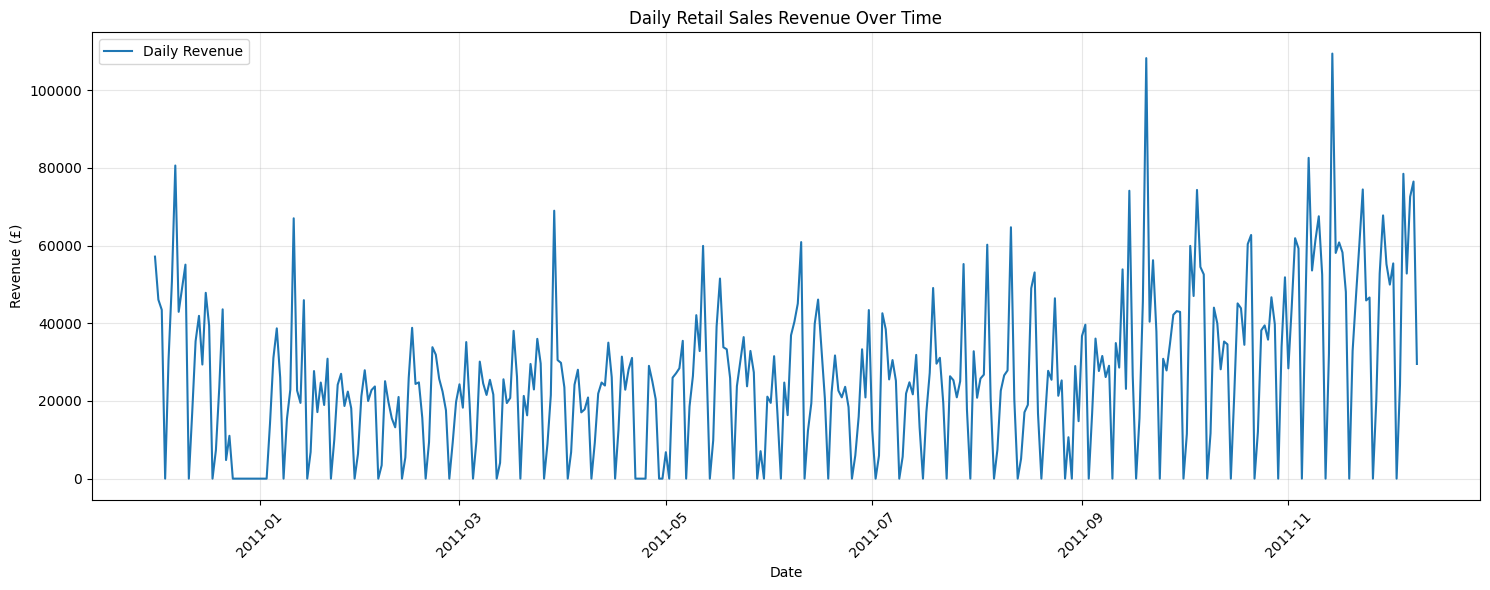

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales.index,
    daily_sales["Daily_Revenue"],
    label="Daily Revenue"
)

plt.title("Daily Retail Sales Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
# Calculate monthly revenue
monthly_sales = daily_sales.resample("ME").agg(
    Monthly_Revenue=("Daily_Revenue", "sum"),
    Average_Daily_Revenue=("Daily_Revenue", "mean"),
    Total_Transactions=("Transaction_Count", "sum")
)

display(monthly_sales)

,Monthly_Revenue,Average_Daily_Revenue,Total_Transactions
InvoiceDate,,,
2010-12-31,756960.860,24418.092258,1863
2011-01-31,578006.290,18645.364194,1331
2011-02-28,497692.220,17774.722143,1296
2011-03-31,679362.880,21914.931613,1729
2011-04-30,480123.291,16004.109700,1461
2011-05-31,730415.210,23561.780968,1949
2011-06-30,723019.750,24100.658333,1835
2011-07-31,677209.481,21845.467129,1694
2011-08-31,699193.830,22554.639677,1595


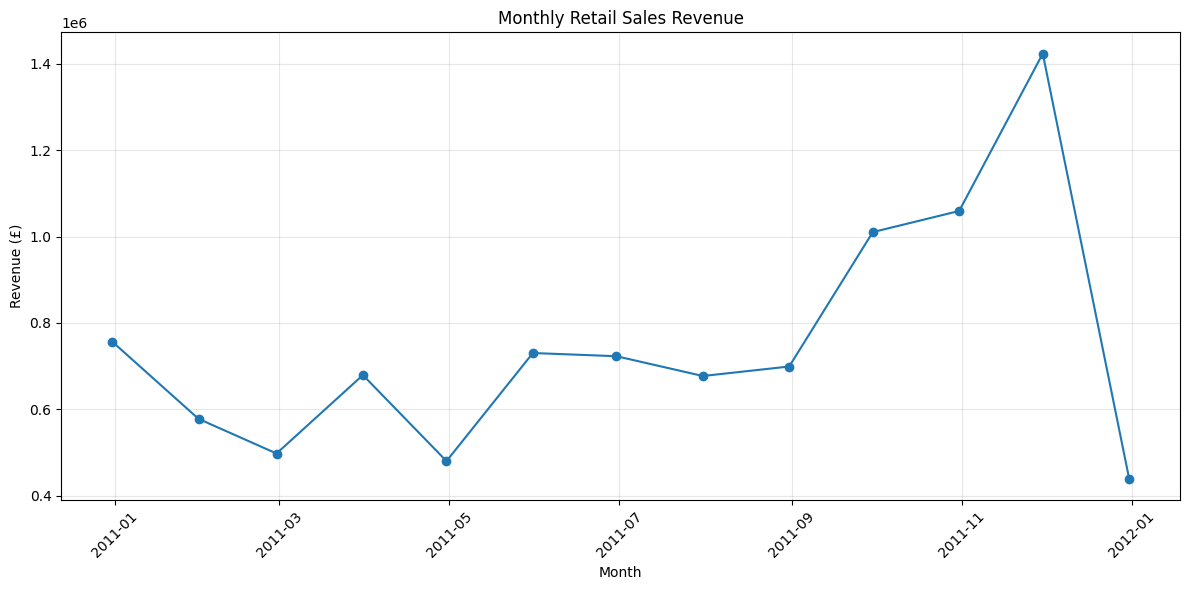

In [24]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales["Monthly_Revenue"],
    marker="o"
)

plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# Identify days with zero revenue
zero_days = daily_sales[
    daily_sales["Daily_Revenue"] == 0
]

print("Number of zero-revenue days:", len(zero_days))

display(zero_days)

Number of zero-revenue days: 69


,Daily_Revenue,Transaction_Count,Total_Quantity
InvoiceDate,,,
2010-12-04,0.0,0,0
2010-12-11,0.0,0,0
2010-12-18,0.0,0,0
2010-12-24,0.0,0,0
2010-12-25,0.0,0,0
...,...,...,...
2011-11-05,0.0,0,0
2011-11-12,0.0,0,0
2011-11-19,0.0,0,0


In [26]:
# Display exact monthly revenue values

monthly_summary = monthly_sales.copy()

monthly_summary.index = monthly_summary.index.strftime("%Y-%m")

display(monthly_summary.round(2))

print("Highest revenue month:")
print(monthly_sales["Monthly_Revenue"].idxmax())
print(monthly_sales["Monthly_Revenue"].max())

print("\nLowest revenue month:")
print(monthly_sales["Monthly_Revenue"].idxmin())
print(monthly_sales["Monthly_Revenue"].min())

,Monthly_Revenue,Average_Daily_Revenue,Total_Transactions
InvoiceDate,,,
2010-12,756960.86,24418.09,1863
2011-01,578006.29,18645.36,1331
2011-02,497692.22,17774.72,1296
2011-03,679362.88,21914.93,1729
2011-04,480123.29,16004.11,1461
2011-05,730415.21,23561.78,1949
2011-06,723019.75,24100.66,1835
2011-07,677209.48,21845.47,1694
2011-08,699193.83,22554.64,1595


Highest revenue month:
2011-11-30 00:00:00
1423835.21

Lowest revenue month:
2011-12-31 00:00:00
439493.77


In [27]:
# Compare September, October and November 2011

comparison = daily_sales.loc[
    "2011-09-01":"2011-11-30"
].resample("ME").agg(
    Monthly_Revenue=("Daily_Revenue", "sum"),
    Total_Transactions=("Transaction_Count", "sum"),
    Total_Quantity=("Total_Quantity", "sum")
)

comparison["Revenue_Per_Transaction"] = (
    comparison["Monthly_Revenue"] /
    comparison["Total_Transactions"]
)

display(comparison.round(2))

,Monthly_Revenue,Total_Transactions,Total_Quantity,Revenue_Per_Transaction
InvoiceDate,,,,
2011-09-30,1010464.17,2133,561725,473.73
2011-10-31,1059368.07,2329,597342,454.86
2011-11-30,1423835.21,3163,734650,450.15


In [28]:
monthly_quantity_per_transaction = (
    daily_sales.loc["2011-09-01":"2011-11-30"]
    .resample("ME")
    .agg(
        Total_Quantity=("Total_Quantity", "sum"),
        Total_Transactions=("Transaction_Count", "sum")
    )
)

monthly_quantity_per_transaction["Avg_Quantity_Per_Transaction"] = (
    monthly_quantity_per_transaction["Total_Quantity"]
    / monthly_quantity_per_transaction["Total_Transactions"]
)

display(monthly_quantity_per_transaction.round(2))

,Total_Quantity,Total_Transactions,Avg_Quantity_Per_Transaction
InvoiceDate,,,
2011-09-30,561725,2133,263.35
2011-10-31,597342,2329,256.48
2011-11-30,734650,3163,232.26


In [29]:
november_products = (
    df_sales[
        (df_sales["InvoiceDate"] >= "2011-11-01") &
        (df_sales["InvoiceDate"] < "2011-12-01")
    ]
    .groupby("Description")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

display(november_products.head(10).round(2))

,Total_Revenue,Total_Quantity
Description,,
RABBIT NIGHT LIGHT,34343.77,14842
PAPER CHAIN KIT 50'S CHRISTMAS,28853.54,7858
WHITE HANGING HEART T-LIGHT HOLDER,14339.32,4936
POPCORN HOLDER,13961.94,12151
PAPER CHAIN KIT VINTAGE CHRISTMAS,12816.79,3781
REGENCY CAKESTAND 3 TIER,12772.98,966
CHILLI LIGHTS,11475.07,2090
JUMBO BAG RED RETROSPOT,11456.13,5806
HOT WATER BOTTLE KEEP CALM,11436.52,2272


In [30]:
christmas_products = df_sales[
    df_sales["Description"].str.contains(
        "CHRISTMAS", case=False, na=False
    )
]

christmas_monthly = (
    christmas_products
    .set_index("InvoiceDate")
    .resample("ME")
    .agg(
        Monthly_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .loc["2011-09-01":"2011-11-30"]
)

display(christmas_monthly.round(2))

,Monthly_Revenue,Total_Quantity
InvoiceDate,,
2011-09-30,80017.52,57392
2011-10-31,97729.46,77309
2011-11-30,156547.03,99215


In [31]:
print("Start date:", daily_sales.index.min())
print("End date:", daily_sales.index.max())

print("\nMissing values:")
print(daily_sales.isnull().sum())

print("\nNumber of days:", len(daily_sales))

print("\nDaily revenue summary:")
print(daily_sales["Daily_Revenue"].describe().round(2))

Start date: 2010-12-01 00:00:00
End date: 2011-12-09 00:00:00

Missing values:
Daily_Revenue        0
Transaction_Count    0
Total_Quantity       0
dtype: int64

Number of days: 374

Daily revenue summary:
count       374.00
mean      26083.28
std       19966.77
min           0.00
25%       11558.19
50%       24745.86
75%       36649.00
max      109445.93
Name: Daily_Revenue, dtype: float64


In [32]:
# Select the target variable
sales = daily_sales["Daily_Revenue"]

# Split the data chronologically
train = sales.iloc[:-30]
test = sales.iloc[-30:]

print("Training data")
print("Start:", train.index.min())
print("End:", train.index.max())
print("Number of days:", len(train))

print("\nTesting data")
print("Start:", test.index.min())
print("End:", test.index.max())
print("Number of days:", len(test))

Training data
Start: 2010-12-01 00:00:00
End: 2011-11-09 00:00:00
Number of days: 344

Testing data
Start: 2011-11-10 00:00:00
End: 2011-12-09 00:00:00
Number of days: 30


In [33]:
# Naive forecast: use the previous day's revenue
naive_predictions = test.shift(1)

# Use the last training day's revenue for the first test day
naive_predictions.iloc[0] = train.iloc[-1]

# Compare actual and predicted revenue
baseline_results = pd.DataFrame({
    "Actual_Revenue": test,
    "Predicted_Revenue": naive_predictions
})

display(baseline_results.head(10).round(2))

,Actual_Revenue,Predicted_Revenue
InvoiceDate,,
2011-11-10,67555.36,61380.79
2011-11-11,52491.78,67555.36
2011-11-12,0.00,52491.78
2011-11-13,32130.19,0.00
2011-11-14,109445.93,32130.19
2011-11-15,58122.72,109445.93
2011-11-16,60826.82,58122.72
2011-11-17,58248.25,60826.82
2011-11-18,48058.23,58248.25


In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, naive_predictions)

rmse = np.sqrt(
    mean_squared_error(test, naive_predictions)
)

print("Naive Forecast Results")
print("----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

Naive Forecast Results
----------------------
MAE: 25658.13
RMSE: 32419.12


In [35]:
# Calculate the average of the previous 7 days
moving_avg_predictions = (
    sales.shift(1)
    .rolling(window=7)
    .mean()
    .loc[test.index]
)

# Compare actual and predicted revenue
moving_avg_results = pd.DataFrame({
    "Actual_Revenue": test,
    "Predicted_Revenue": moving_avg_predictions
})

display(moving_avg_results.head(10).round(2))

,Actual_Revenue,Predicted_Revenue
InvoiceDate,,
2011-11-10,67555.36,51555.98
2011-11-11,52491.78,52362.02
2011-11-12,0.00,51392.64
2011-11-13,32130.19,51392.64
2011-11-14,109445.93,49965.54
2011-11-15,58122.72,53800.37
2011-11-16,60826.82,54446.68
2011-11-17,58248.25,54367.54
2011-11-18,48058.23,53037.96


In [36]:
mae_7day = mean_absolute_error(
    test, moving_avg_predictions
)

rmse_7day = np.sqrt(
    mean_squared_error(test, moving_avg_predictions)
)

print("7-Day Moving Average Results")
print("----------------------------")
print("MAE:", round(mae_7day, 2))
print("RMSE:", round(rmse_7day, 2))

7-Day Moving Average Results
----------------------------
MAE: 20345.52
RMSE: 26086.03


In [37]:
# Use revenue from the same weekday in the previous week
seasonal_predictions = sales.shift(7).loc[test.index]

# Compare actual and predicted revenue
seasonal_results = pd.DataFrame({
    "Actual_Revenue": test,
    "Predicted_Revenue": seasonal_predictions
})

display(seasonal_results.head(10).round(2))

,Actual_Revenue,Predicted_Revenue
InvoiceDate,,
2011-11-10,67555.36,61913.08
2011-11-11,52491.78,59277.45
2011-11-12,0.00,0.00
2011-11-13,32130.19,42119.91
2011-11-14,109445.93,82602.09
2011-11-15,58122.72,53598.54
2011-11-16,60826.82,61380.79
2011-11-17,58248.25,67555.36
2011-11-18,48058.23,52491.78


In [38]:
mae_seasonal = mean_absolute_error(
    test, seasonal_predictions
)

rmse_seasonal = np.sqrt(
    mean_squared_error(test, seasonal_predictions)
)

print("7-Day Seasonal Naive Results")
print("-----------------------------")
print("MAE:", round(mae_seasonal, 2))
print("RMSE:", round(rmse_seasonal, 2))

7-Day Seasonal Naive Results
-----------------------------
MAE: 11109.39
RMSE: 16885.36


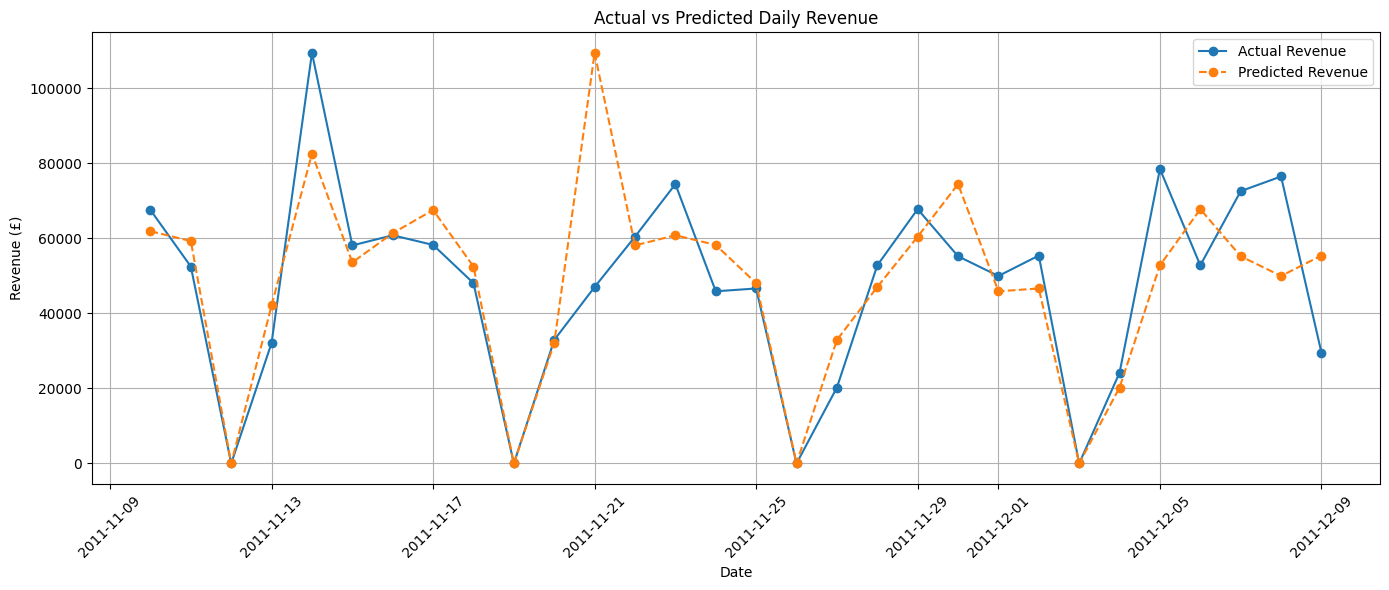

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual Revenue",
    marker="o"
)

plt.plot(
    seasonal_predictions.index,
    seasonal_predictions.values,
    label="Predicted Revenue",
    marker="o",
    linestyle="--"
)

plt.title("Actual vs Predicted Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
nonzero_test = test[test > 0]
nonzero_predictions = seasonal_predictions.loc[nonzero_test.index]

print("MAE on days with sales:",
      round(mean_absolute_error(nonzero_test, nonzero_predictions), 2))

print("RMSE on days with sales:",
      round(np.sqrt(mean_squared_error(nonzero_test, nonzero_predictions)), 2))

MAE on days with sales: 12818.53
RMSE on days with sales: 18137.78


In [41]:
ml_data = pd.DataFrame(index=sales.index)

# Historical revenue features
ml_data["Revenue_Lag_1"] = sales.shift(1)
ml_data["Revenue_Lag_7"] = sales.shift(7)

# Rolling average of previous 7 days
ml_data["Rolling_Mean_7"] = (
    sales.shift(1).rolling(window=7).mean()
)

# Calendar features
ml_data["Day_Of_Week"] = sales.index.dayofweek
ml_data["Month"] = sales.index.month

# Target variable
ml_data["Target"] = sales

# Remove rows with missing feature values
ml_data = ml_data.dropna()

display(ml_data.head())
print("Dataset shape:", ml_data.shape)

,Revenue_Lag_1,Revenue_Lag_7,Rolling_Mean_7,Day_Of_Week,Month,Target
InvoiceDate,,,,,,
2010-12-08,80625.34,57167.10,44092.475714,2,12,42953.84
2010-12-09,42953.84,46070.32,42062.010000,3,12,49040.47
2010-12-10,49040.47,43465.65,42486.317143,4,12,55103.20
2010-12-11,55103.20,0.00,44148.824286,5,12,0.00
2010-12-12,0.00,30517.67,44148.824286,6,12,17037.50


Dataset shape: (367, 6)


In [42]:
# Separate input features and target
X = ml_data.drop(columns=["Target"])
y = ml_data["Target"]

# Chronological split: last 30 days for testing
X_train = X.iloc[:-30]
X_test = X.iloc[-30:]

y_train = y.iloc[:-30]
y_test = y.iloc[-30:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining dates:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting dates:")
print(X_test.index.min(), "to", X_test.index.max())

Training features: (337, 5)
Testing features: (30, 5)

Training dates:
2010-12-08 00:00:00 to 2011-11-09 00:00:00

Testing dates:
2011-11-10 00:00:00 to 2011-12-09 00:00:00


In [43]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict revenue for the test period
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [44]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

print("Random Forest Results")
print("----------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))

Random Forest Results
----------------------
MAE: 10200.21
RMSE: 16859.27


In [45]:
rf_results = pd.DataFrame({
    "Actual_Revenue": y_test,
    "Predicted_Revenue": rf_predictions
})

display(rf_results.round(2))

,Actual_Revenue,Predicted_Revenue
InvoiceDate,,
2011-11-10,67555.36,51630.95
2011-11-11,52491.78,51627.54
2011-11-12,0.00,37.23
2011-11-13,32130.19,29034.89
2011-11-14,109445.93,43421.29
2011-11-15,58122.72,58229.00
2011-11-16,60826.82,51956.50
2011-11-17,58248.25,51473.52
2011-11-18,48058.23,54924.76


Revenue_Lag_7     0.3729
Day_Of_Week       0.2779
Rolling_Mean_7    0.1989
Revenue_Lag_1     0.0888
Month             0.0615
dtype: float64

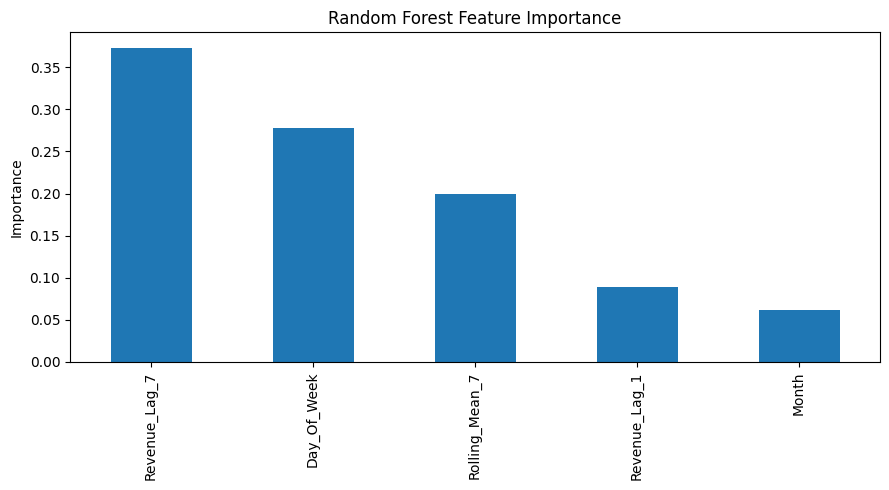

In [57]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(feature_importance.round(4))

feature_importance.plot(
    kind="bar",
    figsize=(9, 5),
    title="Random Forest Feature Importance"
)

plt.ylabel("Importance")
plt.tight_layout()
plt.savefig(
      "../images/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

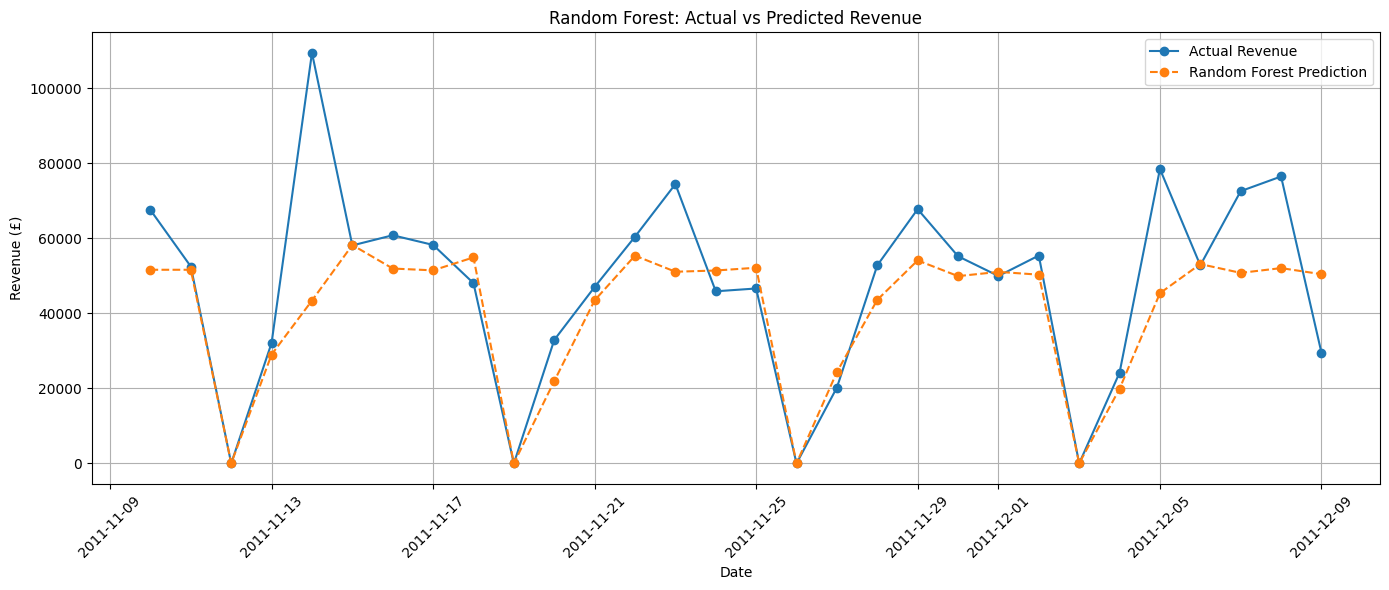

In [54]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index, y_test.values,
    label="Actual Revenue",
    marker="o"
)

plt.plot(
    y_test.index, rf_predictions,
    label="Random Forest Prediction",
    linestyle="--",
    marker="o"
)

plt.title("Random Forest: Actual vs Predicted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig(
      "../images/actual_vs_predicted_revenue.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [48]:
rf_results = pd.DataFrame({
    "Actual_Revenue": y_test,
    "Predicted_Revenue": rf_predictions
})

rf_results["Error"] = (
    rf_results["Actual_Revenue"] -
    rf_results["Predicted_Revenue"]
)

display(rf_results.round(2))

,Actual_Revenue,Predicted_Revenue,Error
InvoiceDate,,,
2011-11-10,67555.36,51630.95,15924.41
2011-11-11,52491.78,51627.54,864.24
2011-11-12,0.00,37.23,-37.23
2011-11-13,32130.19,29034.89,3095.30
2011-11-14,109445.93,43421.29,66024.64
2011-11-15,58122.72,58229.00,-106.28
2011-11-16,60826.82,51956.50,8870.32
2011-11-17,58248.25,51473.52,6774.73
2011-11-18,48058.23,54924.76,-6866.53


In [49]:
rf_results["Absolute_Error"] = (
    rf_results["Error"].abs()
)

display(
    rf_results[
        ["Actual_Revenue", "Predicted_Revenue",
         "Error", "Absolute_Error"]
    ].round(2)
)

,Actual_Revenue,Predicted_Revenue,Error,Absolute_Error
InvoiceDate,,,,
2011-11-10,67555.36,51630.95,15924.41,15924.41
2011-11-11,52491.78,51627.54,864.24,864.24
2011-11-12,0.00,37.23,-37.23,37.23
2011-11-13,32130.19,29034.89,3095.30,3095.30
2011-11-14,109445.93,43421.29,66024.64,66024.64
2011-11-15,58122.72,58229.00,-106.28,106.28
2011-11-16,60826.82,51956.50,8870.32,8870.32
2011-11-17,58248.25,51473.52,6774.73,6774.73
2011-11-18,48058.23,54924.76,-6866.53,6866.53


In [50]:
print("Average Absolute Error:",
      rf_results["Absolute_Error"].mean())

print("Maximum Absolute Error:",
      rf_results["Absolute_Error"].max())

print("Minimum Absolute Error:",
      rf_results["Absolute_Error"].min())

print("Underestimated Days:",
      (rf_results["Error"] > 0).sum())

print("Overestimated Days:",
      (rf_results["Error"] < 0).sum())

Average Absolute Error: 10200.20840326099
Maximum Absolute Error: 66024.63703232954
Minimum Absolute Error: 37.22602857142857
Underestimated Days: 18
Overestimated Days: 12


In [51]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "7-Day Moving Average",
        "7-Day Seasonal Naive",
        "Random Forest"
    ],
    "MAE": [
        25658.13,
        20345.52,
        11109.39,
        10200.21
    ],
    "RMSE": [
        32419.12,
        26086.03,
        16885.36,
        16859.27
    ]
})

display(model_comparison)

,Model,MAE,RMSE
0,Naive,25658.13,32419.12
1,7-Day Moving Average,20345.52,26086.03
2,7-Day Seasonal Naive,11109.39,16885.36
3,Random Forest,10200.21,16859.27


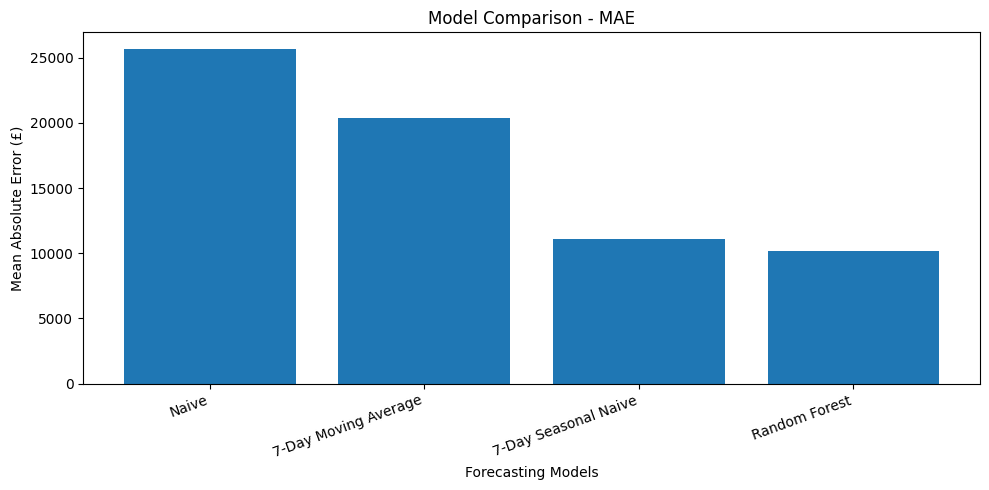

In [55]:
# MAE comparison
plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["MAE"]
)

plt.title("Model Comparison - MAE")
plt.xlabel("Forecasting Models")
plt.ylabel("Mean Absolute Error (£)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.savefig(
    "../images/model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

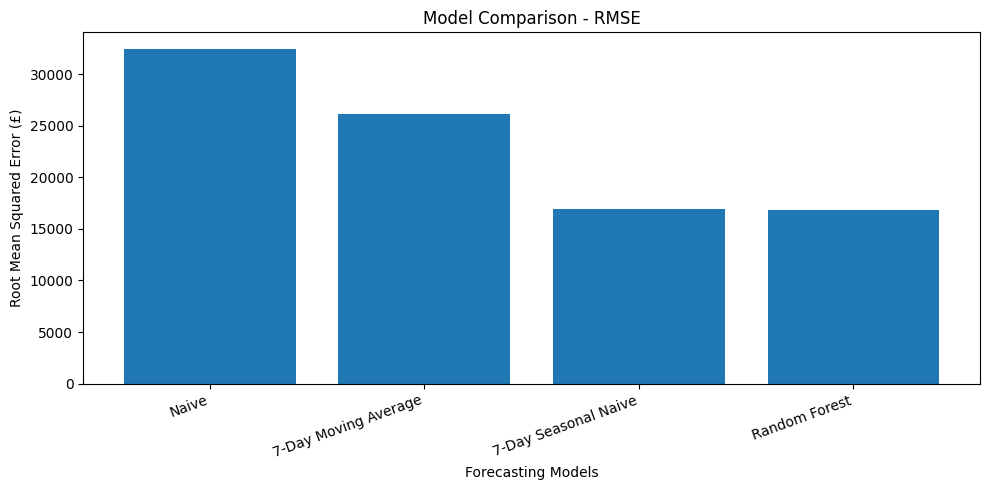

In [56]:
# RMSE comparison
plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["RMSE"]
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Forecasting Models")
plt.ylabel("Root Mean Squared Error (£)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.savefig(
     "../images/model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# **Model Comparison - Key Findings**

- The Naive model had the highest forecasting error.
- The 7-Day Moving Average performed better than the Naive model.
- The 7-Day Seasonal Naive model showed a significant improvement.
- The Random Forest model achieved the lowest MAE and RMSE.
- Random Forest performed slightly better than the Seasonal Naive model.

The results indicate that using previous sales values, weekday information, and rolling averages can improve daily revenue forecasting.

## **Conclusion**

This project focused on analysing an online retail dataset to understand sales patterns and forecast daily revenue. The analysis identified November 2011 as the highest-revenue month in the available data and showed an increase in Christmas-related product revenue from September to November. Four forecasting models were developed and evaluated: Naive, 7-Day Moving Average, 7-Day Seasonal Naive, and Random Forest. Among these, the Random Forest model achieved the lowest MAE of £10,200.21 and RMSE of £16,859.27. The feature importance analysis showed that previous week's revenue and day of the week played important roles in forecasting. However, the model struggled to predict sudden revenue spikes and extreme fluctuations. Overall, this project provided practical experience in data cleaning, exploratory data analysis, feature engineering, model evaluation, and applying machine learning techniques to retail revenue forecasting.